## Library Management

In [ ]:
!pip install cvxpy
!pip install yfinance
!pip install sklearn
!pip install seaborn

  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas import read_csv, set_option
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from datetime import date
import yfinance as yf
import seaborn as sn

#Import Model Packages
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import fcluster
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from sklearn.metrics import adjusted_mutual_info_score
from sklearn import cluster, covariance, manifold
from sklearn.utils import resample
from sklearn.linear_model import LassoCV, Lasso
from sklearn.model_selection import RepeatedKFold
from statsmodels.regression.linear_model import OLS

#Package for optimization of mean variance optimization
import cvxpy as cp
import cvxopt as opt
from cvxopt import blas, solvers

## Data Download and Cleaning

In [ ]:
tickers = ["ORCL", "LLY", "BARC.L", "SKX", "SPGI", "UL", "ARCAD.AS", "AMT"]
dataset = yf.download(tickers, start="2016-01-02", end="2024-07-15")["Close"]



[*********************100%%**********************]  8 of 8 completed


In [ ]:
set_option('display.width', 100)
dataset.head(5)

Ticker,AMT,ARCAD.AS,BARC.L,LLY,ORCL,SKX,SPGI,UL
Date,,,,,,,,
2016-01-04,96.699997,17.587645,214.250000,82.870003,35.750000,29.959999,94.800003,42.200001
2016-01-05,98.610001,17.723757,215.250000,84.110001,35.639999,29.129999,95.120003,42.099998
2016-01-06,98.260002,17.466116,211.750000,83.580002,35.820000,28.870001,94.080002,41.500000
2016-01-07,95.809998,17.359171,205.550003,81.410004,35.040001,27.940001,91.120003,40.849998
2016-01-08,94.230003,17.203613,200.149994,81.250000,34.650002,26.770000,88.510002,40.450001


In [ ]:
print('Null Values =',dataset.isnull().values.any())
dataset.shape

Null Values = True


(2204, 8)

In [ ]:
missing_fractions = dataset.isnull().mean().sort_values(ascending=False)

missing_fractions.head(10)

drop_list = sorted(list(missing_fractions[missing_fractions > 0.9999].index))

dataset.drop(labels=drop_list, axis=1, inplace=True)
dataset.shape

(2204, 8)

In [ ]:
dataset=dataset.fillna(method='ffill')
dataset.head(2)

Ticker,AMT,ARCAD.AS,BARC.L,LLY,ORCL,SKX,SPGI,UL
Date,,,,,,,,
2016-01-04,96.699997,17.587645,214.25,82.870003,35.750000,29.959999,94.800003,42.200001
2016-01-05,98.610001,17.723757,215.25,84.110001,35.639999,29.129999,95.120003,42.099998


In [ ]:
X= dataset.copy('deep')
row= len(X)
train_len = int(row*.3)

In [ ]:
X_train = X.head(train_len)
X_test = X.tail(row-train_len)

#Calculate percentage return
returns = X_train.pct_change().dropna()
returns_test=X_test.pct_change().dropna()


## Portfolio Optimisation Fucntions

In [ ]:
def correlDist(corr):
    # A distance matrix based on correlation, where 0<=d[i,j]<=1
    # This is a proper distance metric
    dist = ((1 - corr) / 2.)**.5  # distance matrix
    return dist

def getQuasiDiag(link):
    # Sort clustered items by distance
    link = link.astype(int)
    sortIx = pd.Series([link[-1, 0], link[-1, 1]])
    numItems = link[-1, 3]  # number of original items
    while sortIx.max() >= numItems:
        sortIx.index = range(0, sortIx.shape[0] * 2, 2)  # make space
        df0 = sortIx[sortIx >= numItems]  # find clusters
        i = df0.index
        j = df0.values - numItems
        sortIx[i] = link[j, 0]  # item 1
        df0 = pd.Series(link[j, 1], index=i + 1)
        sortIx = sortIx._append(df0)  # item 2
        sortIx = sortIx.sort_index()  # re-sort
        sortIx.index = range(sortIx.shape[0])  # re-index
    return sortIx.tolist()

def getClusterVar(cov,cItems):
    # Compute variance per cluster
    cov_=cov.loc[cItems,cItems] # matrix slice
    w_=getIVP(cov_).reshape(-1,1)
    cVar=np.dot(np.dot(w_.T,cov_),w_)[0,0]
    return cVar



def getRecBipart(cov, sortIx):
    # Compute HRP alloc
    w = pd.Series(1, index=sortIx)
    cItems = [sortIx]  # initialize all items in one cluster
    while len(cItems) > 0:
        cItems = [i[j:k] for i in cItems for j, k in ((0, len(i) // 2), (len(i) // 2, len(i))) if len(i) > 1]  # bi-section
        for i in range(0, len(cItems), 2):  # parse in pairs
            cItems0 = cItems[i]  # cluster 1
            cItems1 = cItems[i + 1]  # cluster 2
            cVar0 = getClusterVar(cov, cItems0)
            cVar1 = getClusterVar(cov, cItems1)
            alpha = 1 - cVar0 / (cVar0 + cVar1)
            w[cItems0] *= alpha  # weight 1
            w[cItems1] *= 1 - alpha  # weight 2
    return w

def getMVP(cov):

    cov = cov.T.values
    n = len(cov)
    N = 100
    mus = [10 ** (5.0 * t / N - 1.0) for t in range(N)]

    # Convert to cvxopt matrices
    S = opt.matrix(cov)
    #pbar = opt.matrix(np.mean(returns, axis=1))
    pbar = opt.matrix(np.ones(cov.shape[0]))

    # Create constraint matrices
    G = -opt.matrix(np.eye(n))  # negative n x n identity matrix
    h = opt.matrix(0.0, (n, 1))
    A = opt.matrix(1.0, (1, n))
    b = opt.matrix(1.0)


    # Calculate efficient frontier weights using quadratic programming
    solvers.options['show_progress'] = False
    portfolios = [solvers.qp(mu * S, -pbar, G, h, A, b)['x']
                  for mu in mus]
    ## CALCULATE RISKS AND RETURNS FOR FRONTIER
    returns = [blas.dot(pbar, x) for x in portfolios]
    risks = [np.sqrt(blas.dot(x, S * x)) for x in portfolios]
    ## CALCULATE THE 2ND DEGREE POLYNOMIAL OF THE FRONTIER CURVE
    m1 = np.polyfit(returns, risks, 2)
    x1 = np.sqrt(m1[2] / m1[0])
    # CALCULATE THE OPTIMAL PORTFOLIO
    wt = solvers.qp(opt.matrix(x1 * S), -pbar, G, h, A, b)['x']

    return list(wt)

def getIVP(cov, **kargs):
    # Compute the inverse-variance portfolio
    ivp = 1. / np.diag(cov)
    ivp /= ivp.sum()
    return ivp

def getHRP(cov, corr):
    # Construct a hierarchical portfolio
    dist = correlDist(corr)
    link = sch.linkage(dist, 'single')
    #plt.figure(figsize=(20, 10))
    #dn = sch.dendrogram(link, labels=cov.index.values)
    #plt.show()
    sortIx = getQuasiDiag(link)
    sortIx = corr.index[sortIx].tolist()
    hrp = getRecBipart(cov, sortIx)
    return hrp.sort_index()

def equally_weighted(tickers):
  ew = pd.Series(np.ones(len(returns.columns)) / len(returns.columns), index = tickers)
  return ew

def market_weighted(tickers):
  market_caps = {}
  for ticker in tickers:
    stock = yf.Ticker(ticker)
    market_caps[ticker] = stock.info['marketCap']
  print(market_caps)

  mcap_df = pd.DataFrame(list(market_caps.items()), columns=['Ticker', 'MarketCap'])

  # Calculate total market capitalization
  total_market_cap = mcap_df['MarketCap'].sum()

  # Calculate weights for each asset
  mcap_df['Weight'] = mcap_df['MarketCap'] / total_market_cap

  return list(mcap_df['Weight'])

def get_all_portfolios(returns):

    cov, corr = returns.cov(), returns.corr()
    hrp = getHRP(cov, corr)
    mvp = getMVP(cov)
    mvp = pd.Series(mvp, index=cov.index)
    ew = equally_weighted(returns.columns)
    mw = pd.Series(market_weighted(returns.columns), index = returns.columns)
    portfolios = pd.DataFrame([mvp, hrp, ew, mw], index=['MVP', 'HRP', 'EW', 'MW']).T
    #portfolios = pd.DataFrame([ivp, hrp], index=['IVP', 'HRP']).T
    return portfolios


##Alternative models





Equally Weighted - Done





Value Weighted - Done

http://faculty.london.edu/avmiguel/DeMiguel-Garlappi-Uppal-RFS.pdf

Maximum Quadratic Utility

Minimum CVaR

https://www.ise.ufl.edu/uryasev/files/2011/11/CVaR1_JOR.pdf

https://en.wikipedia.org/wiki/Expected_shortfall

Risk Parity Approach - Done


https://thequantmba.wordpress.com/2016/12/14/risk-parityrisk-budgeting-portfolio-in-python/

Mixture - Minimum Variance and Equally Weighted - Done

http://faculty.london.edu/avmiguel/DeMiguel-Garlappi-Uppal-RFS.pdf

## Building Portfolios

In [ ]:
dist = correlDist(returns.corr())
link = linkage(dist, 'complete')
link[0]

<ipython-input-11-477a09a52e62>:2: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  link = linkage(dist, 'complete')


array([4.        , 6.        , 0.72249485, 2.        ])

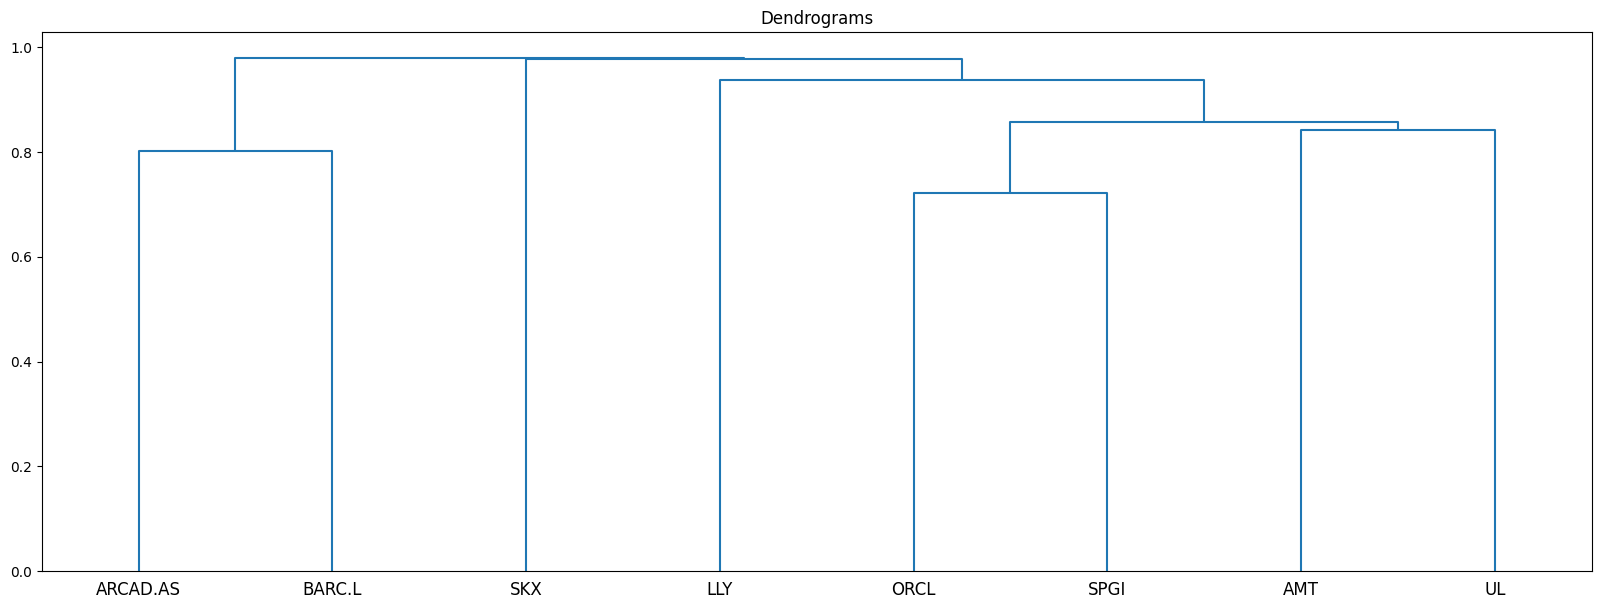

In [ ]:
#Plot Dendogram
plt.figure(figsize=(20, 7))
plt.title("Dendrograms")
dendrogram(link,labels = X.columns)
plt.show()

<ipython-input-10-ec1b08005dcc>:92: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  link = sch.linkage(dist, 'single')
<ipython-input-10-ec1b08005dcc>:76: RankWarning: Polyfit may be poorly conditioned
  m1 = np.polyfit(returns, risks, 2)


{'AMT': 98174492672, 'ARCAD.AS': 5717816320, 'BARC.L': 33999212544, 'LLY': 793103761408, 'ORCL': 393261219840, 'SKX': 9969272832, 'SPGI': 155060715520, 'UL': 143003238400}


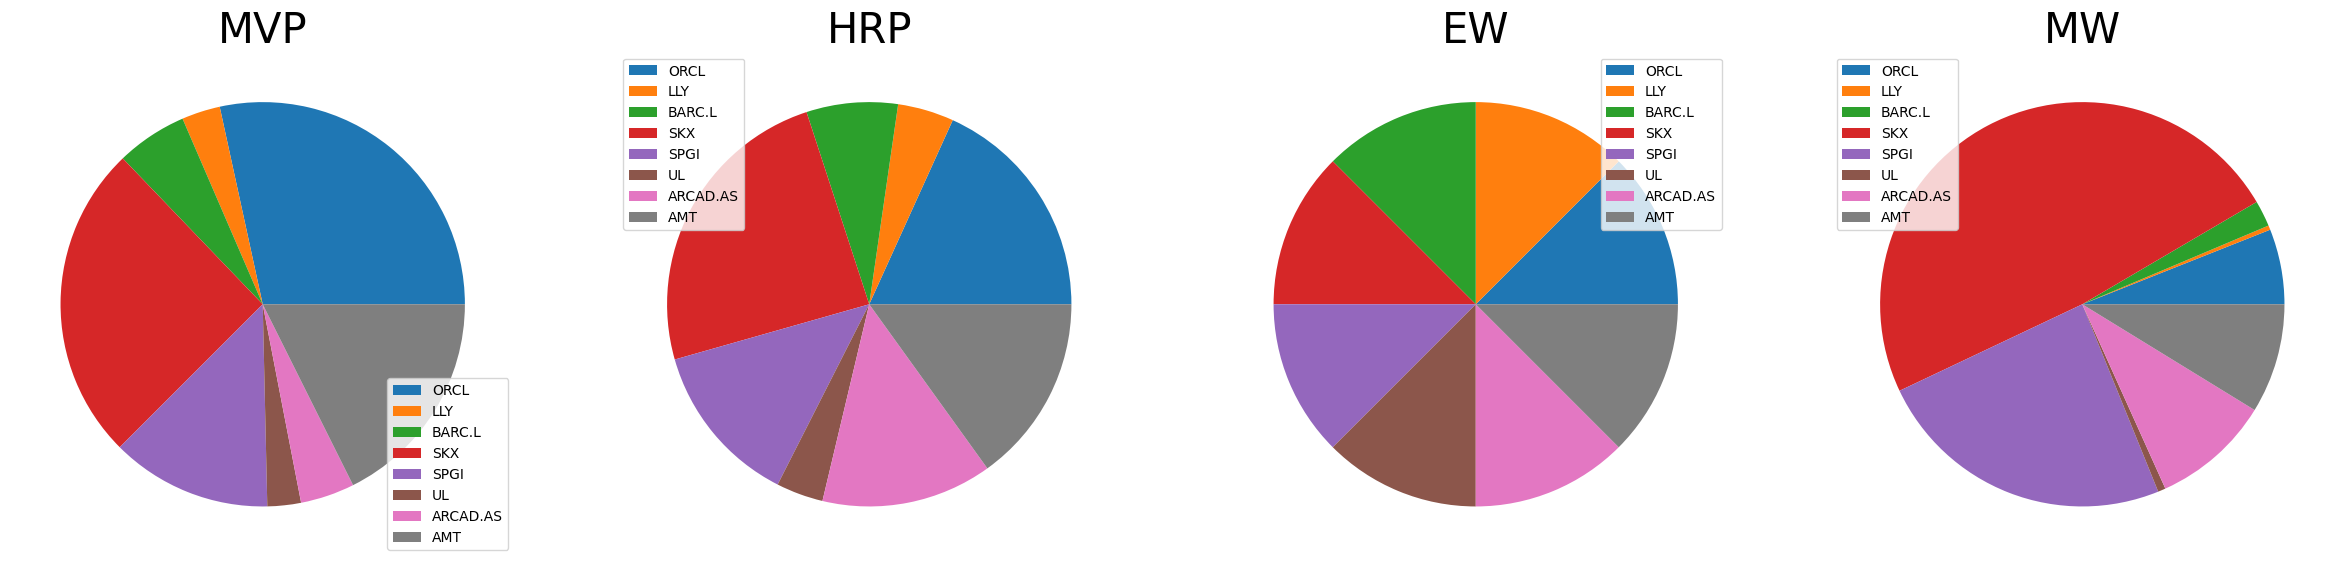

In [ ]:
portfolios = get_all_portfolios(returns)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4,figsize=(30,20))
ax1.pie(portfolios.iloc[:,0], );
ax1.set_title('MVP',fontsize = 30)
ax1.legend(tickers)
ax2.pie(portfolios.iloc[:,1]);
ax2.set_title('HRP',fontsize = 30)
ax2.legend(tickers)
ax3.pie(portfolios.iloc[:,2]);
ax3.set_title('EW',fontsize = 30)
ax3.legend(tickers)
ax4.pie(portfolios.iloc[:,3]);
ax4.set_title('MW',fontsize = 30)
ax4.legend(tickers)
#portfolios.plot.pie(subplots=False, figsize=(20, 10),legend = True);

In [ ]:
print(portfolios)

               MVP       HRP     EW        MW
AMT       0.284143  0.182223  0.125  0.060145
ARCAD.AS  0.030769  0.044923  0.125  0.003503
BARC.L    0.056794  0.073058  0.125  0.020829
LLY       0.253296  0.243845  0.125  0.485884
ORCL      0.128616  0.131146  0.125  0.240926
SKX       0.026812  0.037624  0.125  0.006108
SPGI      0.043306  0.136485  0.125  0.094996
UL        0.176265  0.150696  0.125  0.087609


## Backtesting

<Axes: title={'center': 'Out Of Sample Results'}, xlabel='Date'>

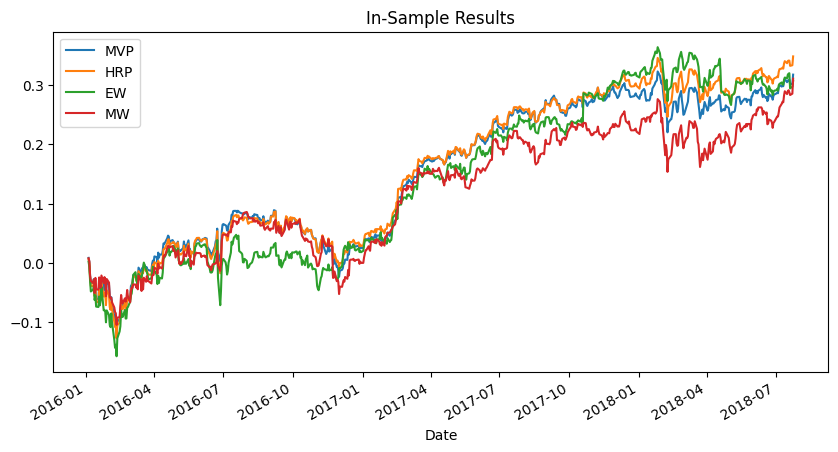

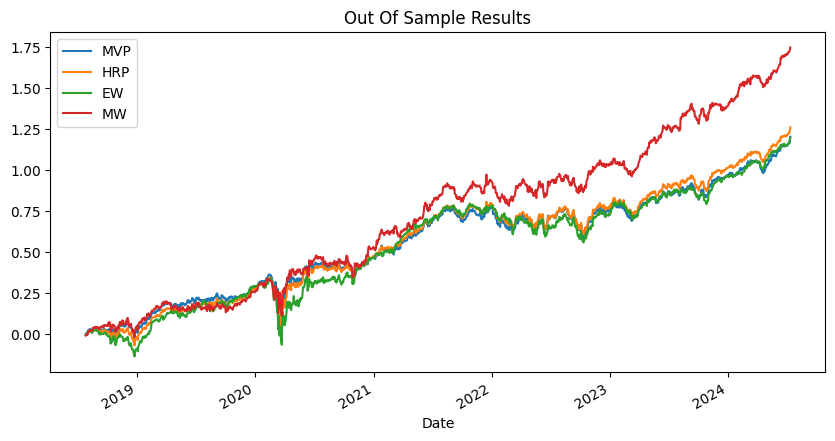

In [ ]:
Insample_Result=pd.DataFrame(np.dot(returns,np.array(portfolios)),
                             columns=['MVP', 'HRP', 'EW', 'MW'], index = returns.index)
OutOfSample_Result=pd.DataFrame(np.dot(returns_test,np.array(portfolios)), \
                                columns=['MVP', 'HRP', 'EW', 'MW'], index = returns_test.index)

Insample_Result.cumsum().plot(figsize=(10, 5), title ="In-Sample Results")
OutOfSample_Result.cumsum().plot(figsize=(10, 5), title ="Out Of Sample Results")

In [ ]:
#In_sample Results
stddev = Insample_Result.std() * np.sqrt(252)
returns = Insample_Result.mean() * np.sqrt(252)
sharpe_ratio = (Insample_Result.mean() * np.sqrt(252))/Insample_Result.std()
Results = pd.DataFrame(dict(returns = returns, stdev=stddev, sharp_ratio = sharpe_ratio))
Results


,returns,stdev,sharp_ratio
MVP,0.007638,0.124653,0.972729
HRP,0.008378,0.127623,1.042077
EW,0.007377,0.150778,0.776723
MW,0.007475,0.141758,0.837047


In [ ]:
#Outof_sample Results
stddev_oos = OutOfSample_Result.std() * np.sqrt(252)
returns = OutOfSample_Result.mean()*np.sqrt(252)
sharpe_ratio_oos = (OutOfSample_Result.mean()*np.sqrt(252))/OutOfSample_Result.std()
Results_oos = pd.DataFrame(dict(returns = returns, stdev_oos=stddev_oos, sharpe_ratio_oos = sharpe_ratio_oos))
Results_oos

,returns,stdev_oos,sharpe_ratio_oos
MVP,0.012370,0.187993,1.044529
HRP,0.012969,0.185989,1.106903
EW,0.012312,0.190972,1.023431
MW,0.017971,0.213928,1.333534


## Return Metrics

Arithmetic Mean (monthly, annualised, entire period)

In [ ]:
def annualized_return(dataframe, return_column, periods_per_year):

  total_period_return = dataframe[return_column].iloc[-1]  # Get the last cumulative return
  total_periods = len(dataframe)
  years = total_periods / periods_per_year

  annualized_return = (1 + total_period_return) ** (1 / years) - 1
  return annualized_return

print(annualized_return(Insample_Result,["HRP", "MW"], 252))

HRP    0.005659
MW     0.009577
Name: 2018-07-24 00:00:00, dtype: float64


In [ ]:
def cummulative_return(dataframe):
  dataframe = dataframe.cumsum()
  beginning = dataframe.head(1)
  ending = dataframe.tail(1)

  cummulative = pd.DataFrame()
  for portfolio in list(dataframe.columns):
    cummulative[portfolio] = int(ending[portfolio])/(beginning[portfolio])

  cummulative = cummulative.reset_index(drop = True)
  return cummulative

print(cummulative_return(Insample_Result))

   MVP  HRP   EW   MW
0  0.0  0.0  0.0  0.0


<ipython-input-19-566ac501f0cf>:8: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  cummulative[portfolio] = int(ending[portfolio])/(beginning[portfolio])
<ipython-input-19-566ac501f0cf>:8: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  cummulative[portfolio] = int(ending[portfolio])/(beginning[portfolio])
<ipython-input-19-566ac501f0cf>:8: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  cummulative[portfolio] = int(ending[portfolio])/(beginning[portfolio])
<ipython-input-19-566ac501f0cf>:8: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  cummulative[portfolio] = int(ending[portfolio])/(beginning[portfolio])


Alpha(annualised)

Positive Periods

Negative Periods

## Risk Metrics

Standard Deviation(monthly, annualised, entire period)

In [ ]:
def Standard_Deviation(dataframe, period):
  stddev = dataframe.std() * np.sqrt(period)
  return stddev

print(Standard_Deviation(Insample_Result, period = 252))

MVP    0.124653
HRP    0.127623
EW     0.150778
MW     0.141758
dtype: float64


Maximum Drawdown

Historical Value At Risk (5%)

Expected Shortfall

Beta

In [ ]:


def Portfolio_Beta(Portfolio_Ret, benchmark, model, benchmark_ticker):
  factors = yf.download(list(), start="2016-01-02", end="2024-04-22")["Close"]
  model = OLS(Portfolio_Ret[model], benchmark[benchmark_ticker])
  results = model.fit()
  results = results.params
  beta = results[0]

  return(float(beta))

Skewness

Excess Kurtosis

## Risk and Return Metrics

Sharpe Ratio

Sortino Ratio

Tracking Error

Treynor Ratio

Calmar Ratio

Information Ratio

Capture Ratios

Downside Capture Ratio (%)

R-Squared

Fundamental perspective

-GICS exposure
-Valuation Ratios
-Momentum indicators
-Market Capitalisation
-Measures of Quality
-ESG criteria

Use pie charts, line scale, histograms

Use standardized scale 1-0 (1 biggest, 0 smallest)

## Factor Loadings

Getting ETF's associated to specific factors

In [ ]:
#creating dictionary containing the mapping of market ETF's
#key=factor name, value = yahoo finance etf ticker
factor_mapping = {
   "^SPX": "Market US",  # S&P 500 Index
    "^STOXX50E": "Market EU",  # EURO STOXX 50 Index
    "EEMA": "Market Asia",  # iShares MSCI Emerging Markets Asia ETF
    "^RUT": "Market UK",  # Russell 2000 Index (US small-cap stocks), originally incorrect for UK
    "URTH": "Market World",  # iShares MSCI World ETF
    "VTV": "Value Factor",  # Vanguard Value ETF
    "IWSZ.L": "Size Factor",  # iShares MSCI World Size Factor UCITS ETF
    "LQDH": "Interest Corporate",  # iShares Interest Rate Hedged Corporate Bond ETF
    "VEU": "FTSE ALL WORLD",  # Vanguard FTSE All-World ex-US ETF
    "ISF.L": "FTSE100",  # iShares FTSE 100 UCITS ETF (Acc)
    "DAX": "DAX30",  # Global X DAX Germany ETF
    "IFEU": "STOXX EU REITS",  # iShares Europe Developed Real Estate ETF
    'SPY': 'SPDR S&P 500 ETF Trust',
    'IVV': 'iShares Core S&P 500 ETF',
    'VTI': 'Vanguard Total Stock Market ETF',
    'QQQ': 'Invesco QQQ Trust',
    'VXUS': 'Vanguard Total International Stock ETF',
    'VEA': 'Vanguard FTSE Developed Markets ETF',
    'VGK': 'Vanguard FTSE Europe ETF',
    'EWU': 'iShares MSCI United Kingdom ETF',
    'EZU': 'iShares MSCI Eurozone ETF',
    'IEFA': 'iShares Core MSCI EAFE ETF',
    'EEM': 'iShares MSCI Emerging Markets ETF',
    'VWO': 'Vanguard FTSE Emerging Markets ETF',
    'BNDX': 'Vanguard Total International Bond ETF',
    'GLD': 'SPDR Gold Trust',
    'SLV': 'iShares Silver Trust',
    'DBC': 'Invesco DB Commodity Index Tracking Fund',
    'IEMG': 'iShares Core MSCI Emerging Markets ETF',
    'IEUR': 'iShares Core MSCI Europe ETF',
    'EWG': 'iShares MSCI Germany ETF'

    }

factors = yf.download(list(factor_mapping.keys()), start="2016-01-02", end="2024-07-15")["Close"]

[*********************100%%**********************]  31 of 31 completed


Data Cleaning for Factor Loading

In [ ]:
missing_fractions = factors.isnull().mean().sort_values(ascending=False)

missing_fractions.head(10)

drop_list = sorted(list(missing_fractions[missing_fractions > 0.3].index))

factors.drop(labels=drop_list, axis=1, inplace=True)
factors.shape

factors=factors.fillna(method='ffill')
factors.head(10)

X= factors.copy('deep')
row= len(X)
train_len = int(row*.7)

X_train_factors = X.head(train_len)
X_test_factors = X.tail(row-train_len)

#Calculate percentage return
returns_factors = X_train_factors.pct_change().dropna()
returns_factors_test=X_test_factors.pct_change().dropna()

#align dataframes in order to account for dates mismatch
returns_factors.fillna(method='ffill')
returns_factors = returns_factors[returns_factors.index.isin(Insample_Result.index)]
Insample_Result = Insample_Result[Insample_Result.index.isin(returns_factors.index)]

print(returns_factors)
print(Insample_Result)


Ticker          BNDX       DAX       DBC       EEM      EEMA       EWG       EWU       EZU  \
Date                                                                                         
2016-01-05 -0.000566 -0.005836 -0.009804  0.002236  0.004707 -0.009390 -0.002519 -0.008703   
2016-01-06  0.003776 -0.011321 -0.015994 -0.019120 -0.018945 -0.011453 -0.018308 -0.016389   
2016-01-07 -0.001505 -0.017812 -0.004644 -0.030864 -0.024502 -0.019976 -0.027653 -0.013984   
2016-01-08 -0.000188 -0.009499 -0.004666 -0.010727 -0.008514 -0.009784 -0.006614 -0.009052   
2016-01-11 -0.001131  0.007847 -0.027344 -0.000339  0.000000  0.007822  0.002663  0.005481   
...              ...       ...       ...       ...       ...       ...       ...       ...   
2018-07-18 -0.000182  0.001353  0.008987 -0.001138 -0.000289  0.000968 -0.000577  0.000475   
2018-07-19  0.001275 -0.005741 -0.001188 -0.012306 -0.012563 -0.005803 -0.004330 -0.004269   
2018-07-20 -0.001819 -0.002378  0.007134  0.014305  0.013308

Factor Loading Calculation Function

In [ ]:
#select any relevant model from the portfolio model list
#set "show_plots" to True for diagnostics
def factor_exposure(factor_returns, portfolio_returns, model='HRP', negative_values = False):

  #set positive to True, in order to allow for selection and avoid going short on negatively correlated positions
  lasso_cv = LassoCV(n_alphas=1000, cv= RepeatedKFold(n_splits=10, n_repeats=20, random_state=2), selection = 'cyclic', fit_intercept = False, positive = False)
  lasso_cv.fit(factor_returns, portfolio_returns[model])


  #bootstrap results to obtain coefficient significance
  lasso = Lasso(alpha=lasso_cv.alpha_)
  # Number of bootstrap samples
  n_bootstraps = 100
  # Store bootstrap samples coefficients
  bootstrap_coefs = np.zeros((n_bootstraps, factor_returns.shape[1]))
  #obtain number of coefficients
  n_features = factor_returns.shape[1]
  #empty boolean vector
  significant_coefs = np.zeros(n_features, dtype=bool)


  # Generate bootstrap samples and fit Lasso
  for i in range(n_bootstraps):
    # Generate a bootstrap sample from the data
    Xb, yb = resample(factor_returns, portfolio_returns[model])
    # Fit Lasso to the bootstrap sample
    lasso.fit(Xb, yb)
    # Store the coefficients
    bootstrap_coefs[i] = lasso.coef_

  #checks for significance of non-zero coefficients, or negative coefficients
  for i in range(n_features):

    if negative_values == True:
      non_zero_proportion = np.sum(bootstrap_coefs[:, i] != 0) / n_bootstraps
    elif negative_values == False:
      non_zero_proportion = np.sum(bootstrap_coefs[:, i] >= 0.05) / n_bootstraps

    significant_coefs[i] = non_zero_proportion > (1 - 0.05)

  #save beta coefficients for each factor
  coefficients = pd.DataFrame(dict(factor = factor_returns.columns, coefficient = lasso_cv.coef_, significance = significant_coefs))
  mse_mean = np.mean(lasso_cv.mse_path_, axis=1)
  mse_std = np.std(lasso_cv.mse_path_, axis=1)


  return coefficients

def Portfolio_Beta(Portfolio_Ret, benchmark, model, benchmark_ticker):
  model = OLS(Portfolio_Ret[model], benchmark[benchmark_ticker])
  results = model.fit()
  results = results.params
  beta = results[0]

  return(float(beta))

Calling the function

In [ ]:

Factor_coeff = factor_exposure(returns_factors, Insample_Result, model = "HRP", negative_values = False)

Factor_Beta = Factor_coeff.loc[Factor_coeff["significance"] == 1, "coefficient"].to_list()
factor_names = Factor_coeff.loc[Factor_coeff["significance"] == 1, "factor"].to_list()

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.949e-05, tolerance: 4.278e-06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.535e-05, tolerance: 3.987e-06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.579e-06, tolerance: 4.026e

In [ ]:
print(Factor_coeff)

       factor  coefficient  significance
0        BNDX     0.165732         False
1         DAX     0.050025         False
2         DBC    -0.084193         False
3         EEM    -0.000000         False
4        EEMA    -0.028332         False
5         EWG    -0.179055         False
6         EWU    -0.000000         False
7         EZU     0.000000         False
8         GLD     0.086241         False
9        IEFA    -0.041578         False
10       IEMG    -0.127718         False
11       IEUR     0.158165         False
12      ISF.L     0.094549         False
13        IVV    -0.000000         False
14     IWSZ.L    -0.058719         False
15       LQDH     0.065591         False
16        QQQ    -0.164198         False
17        SLV    -0.030999         False
18        SPY     0.386965         False
19       URTH     0.231030          True
20        VEA    -0.000000         False
21        VEU     0.077195         False
22        VGK     0.016113         False
23        VTI   

## Market Neutral Portfolio Construction

In [ ]:
def hedging(factor_coefficients, portf_ret, factor_returns, model):
  Factor_Beta = factor_coefficients.loc[factor_coefficients["significance"] == 1, ["coefficient", "factor"]]
  Factor_Returns = factor_returns[Factor_Beta["factor"]]
  Factor_Beta = Factor_Beta.set_index(Factor_Beta["factor"])["coefficient"]

  Factor_explanation = (Factor_Beta.mul(Factor_Returns))
  Residual = portf_ret[model] - Factor_explanation.sum(axis = 1)
  Explained = portf_ret[model].sub(Residual)
  Factor_Weight = Factor_explanation.sum(axis = 0)/Explained.sum(axis = 0)

  return(Factor_Weight)

print(hedging(Factor_coeff, Insample_Result, returns_factors, model="HRP"))


Ticker
URTH         0.792431
^STOXX50E    0.207569
dtype: float64


In [ ]:
hedging_values = hedging(Factor_coeff, Insample_Result, returns_factors, model="HRP")

## Discrete Allocation

---




In [ ]:
def long_short_weights(model_weights, hedge_weights, hedge_ratio = 1, model_name = "HRP"):
  short_weights = np.float64(hedge_ratio) * -1 * hedge_weights

  global_weights = pd.Series(model_weights[model_name])
  global_weights = pd.concat([global_weights ,short_weights])

  long_weights = pd.concat([model_weights[model_name], pd.Series(np.zeros(len(short_weights)), index = hedge_weights.index)])
  short_weights = pd.concat([pd.Series(np.zeros(len(model_weights)), index = model_weights.index), short_weights])

  global_dict = {"Long + Short": global_weights,
                 "Long": long_weights,
                 "Short": short_weights}
  global_weights = pd.DataFrame(global_dict)

  return(global_weights)

market_neutral_weights = long_short_weights(portfolios, hedging_values, hedge_ratio = 0.7, model_name= "HRP")

print(market_neutral_weights)

           Long + Short      Long     Short
AMT            0.182223  0.182223  0.000000
ARCAD.AS       0.044923  0.044923  0.000000
BARC.L         0.073058  0.073058  0.000000
LLY            0.243845  0.243845  0.000000
ORCL           0.131146  0.131146  0.000000
SKX            0.037624  0.037624  0.000000
SPGI           0.136485  0.136485  0.000000
UL             0.150696  0.150696  0.000000
URTH          -0.554702  0.000000 -0.554702
^STOXX50E     -0.145298  0.000000 -0.145298


[*********************100%%**********************]  10 of 10 completed


<Axes: title={'center': 'In-Sample Results'}, xlabel='Date'>

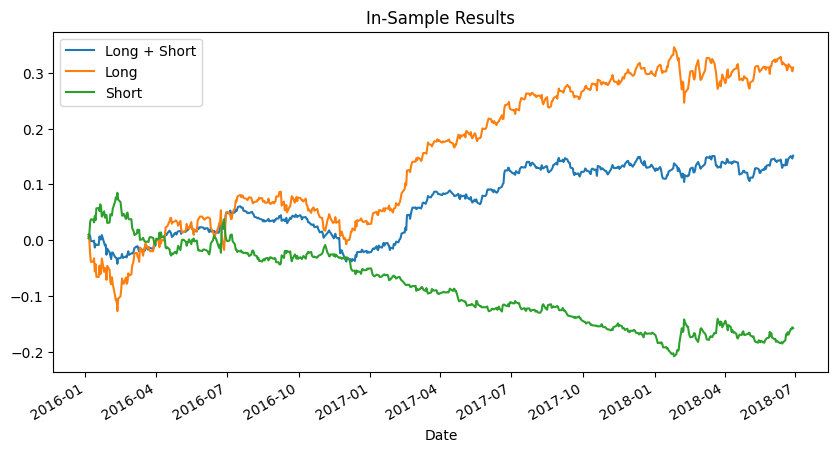

In [ ]:
returns_long_short = yf.download(list(market_neutral_weights.index), start="2016-01-02", end="2024-04-22")['Close']
returns_long_short = returns_long_short.pct_change().dropna()

X= returns_long_short.copy('deep')
row= len(X)
train_len = int(row* .3)

X_train = X.head(train_len)
X_test = X.tail(row-train_len)


Insample_Result_LS=pd.DataFrame(np.dot(X_train,np.array(market_neutral_weights)),columns = ["Long + Short", "Long", "Short"], index= X_train.index)
Insample_Result_LS.cumsum().plot(figsize=(10, 5), title ="In-Sample Results")


In [ ]:
stddev_oos = Insample_Result_LS.std() * np.sqrt(252)
returns = Insample_Result_LS.mean()*np.sqrt(252)
sharpe_ratio_oos = (Insample_Result_LS.mean()*np.sqrt(252))/Insample_Result_LS.std()
Results_LS_oos = pd.DataFrame(dict(returns = returns, stdev_oos=stddev_oos, sharpe_ratio_oos = sharpe_ratio_oos))
Results_LS_oos

,returns,stdev_oos,sharpe_ratio_oos
Long + Short,0.003744,0.075828,0.783885
Long,0.007646,0.128638,0.943554
Short,-0.003902,0.085737,-0.722397


<Axes: title={'center': 'Out-Of-Sample Results'}, xlabel='Date'>

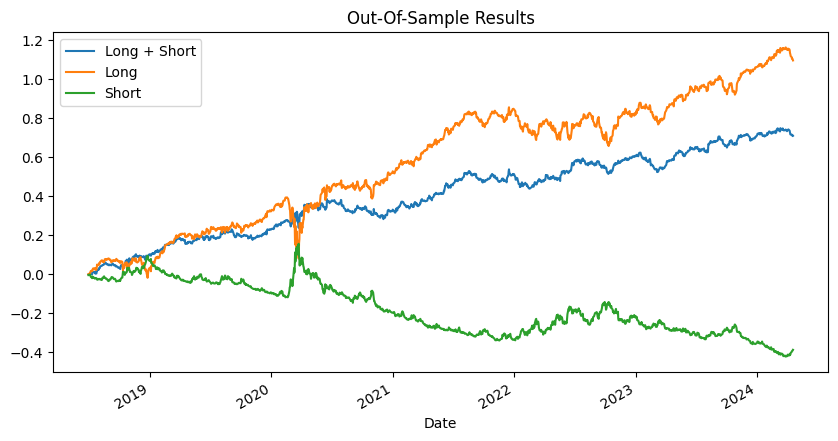

In [ ]:
OutOfSample_Result_LS=pd.DataFrame(np.dot(X_test,np.array(market_neutral_weights)),columns = ["Long + Short", "Long", "Short"], index= X_test.index)
OutOfSample_Result_LS.cumsum().plot(figsize=(10, 5), title ="Out-Of-Sample Results")

In [ ]:
stddev_oos = OutOfSample_Result_LS.std() * np.sqrt(252)
returns = OutOfSample_Result_LS.mean()*np.sqrt(252)
sharpe_ratio_oos = (OutOfSample_Result_LS.mean()*np.sqrt(252))/OutOfSample_Result_LS.std()
Results_LS_oos = pd.DataFrame(dict(returns = returns, stdev_oos=stddev_oos, sharpe_ratio_oos = sharpe_ratio_oos))
Results_LS_oos

,returns,stdev_oos,sharpe_ratio_oos
Long + Short,0.007521,0.107095,1.114894
Long,0.011611,0.187557,0.982702
Short,-0.004089,0.128432,-0.505428


## Discrete Allocation for Trading

In [ ]:
def get_exchange_rate(currency):

    if currency == "GBP":
        return 1.0  # No conversion needed
    elif currency == "GBp":
        return 0.01 # Convert from pence to pounds

    exchange_ticker = f"{currency}GBP=X"
    exchange_data = yf.download(exchange_ticker, period="1d")
    return exchange_data['Close'][0]

def get_currency(symbol):

    ticker = yf.Ticker(symbol)
    info = ticker.info
    return info.get('currency', 'GBP')  # Default to GBP if currency not found

def get_last_price(symbol):
    """
    Get the last price for a given stock symbol.
    """
    ticker = yf.Ticker(symbol)
    price = ticker.history(period="1d")['Close'][0]
    return price

def proportional_allocation(symbols, long_weights, short_weights, total_notional_long):

    # Get last prices and exchange rates, and convert prices to GBP
    prices = {symbol: get_last_price(symbol) for symbol in symbols}
    exchange_rates = {symbol: get_exchange_rate(get_currency(symbol)) for symbol in symbols}
    prices_gbp = {symbol: prices[symbol] * exchange_rates[symbol] for symbol in symbols}

    # Calculate total weight for long and short positions
    total_weight_long = sum(long_weights)
    total_weight_short = sum(short_weights)

    # Calculate total notional for short positions
    total_notional_short = total_notional_long * total_weight_short

    # Create a DataFrame with symbols, prices in GBP, weights, and initial allocation for long and short positions
    data = {
        'Symbol': symbols,
        'Price_GBP': [prices_gbp[symbol] for symbol in symbols],
        'Long_Weight': long_weights,
        'Short_Weight': short_weights
    }
    df = pd.DataFrame(data)

    # Calculate the proportional allocation for long positions
    df['Initial_Allocation_GBP_Long'] = (df['Long_Weight'] / total_weight_long) * total_notional_long
    # Scale allocations to fit within the total notional for long positions
    scaling_factor_long = total_notional_long / df['Initial_Allocation_GBP_Long'].sum()
    df['Allocation_GBP_Long'] = df['Initial_Allocation_GBP_Long'] * scaling_factor_long
    # Calculate the quantities to buy for long positions
    df['Quantity_Long'] = df['Allocation_GBP_Long'] // df['Price_GBP']

    # Calculate the proportional allocation for short positions
    df['Initial_Allocation_GBP_Short'] = (df['Short_Weight'] / total_weight_short) * total_notional_short
    # Scale allocations to fit within the total notional for short positions
    scaling_factor_short = total_notional_short / df['Initial_Allocation_GBP_Short'].sum()
    df['Allocation_GBP_Short'] = df['Initial_Allocation_GBP_Short'] * scaling_factor_short
    # Calculate the quantities to sell for short positions
    df['Quantity_Short'] = df['Allocation_GBP_Short'] // df['Price_GBP']

    return df[[ 'Price_GBP', 'Long_Weight', 'Short_Weight', 'Allocation_GBP_Long', 'Quantity_Long', 'Allocation_GBP_Short', 'Quantity_Short']]



In [ ]:
quantities = proportional_allocation(symbols = market_neutral_weights.index, long_weights = market_neutral_weights["Long"], short_weights = market_neutral_weights["Short"], total_notional_long = 20000)

[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed


In [ ]:
display(quantities)

,Price_GBP,Long_Weight,Short_Weight,Allocation_GBP_Long,Quantity_Long,Allocation_GBP_Short,Quantity_Short
AMT,162.842612,0.182223,0.000000,3644.450493,22.0,0.000000,0.0
ARCAD.AS,53.431570,0.044923,0.000000,898.451575,16.0,0.000000,0.0
BARC.L,2.305000,0.073058,0.000000,1461.162065,633.0,0.000000,0.0
LLY,682.573678,0.243845,0.000000,4876.907830,7.0,0.000000,0.0
ORCL,110.620628,0.131146,0.000000,2622.919365,23.0,0.000000,0.0
SKX,50.631729,0.037624,0.000000,752.489110,14.0,0.000000,0.0
SPGI,384.294563,0.136485,0.000000,2729.705865,7.0,0.000000,0.0
UL,44.407821,0.150696,0.000000,3013.913698,67.0,0.000000,0.0
URTH,116.600541,0.000000,-0.554702,0.000000,0.0,-11094.032049,-96.0
^STOXX50E,4133.947037,0.000000,-0.145298,0.000000,0.0,-2905.967951,-1.0
